Homework Reflection 5

1. Draw a diagram for the following negative feedback loop:

Sweating causes body temperature to decrease.  High body temperature causes sweating.

A negative feedback loop means that one thing increases another while the second thing decreases the first.

Remember that we are using directed acyclic graphs where two things cannot directly cause each other.

Is DAG: True


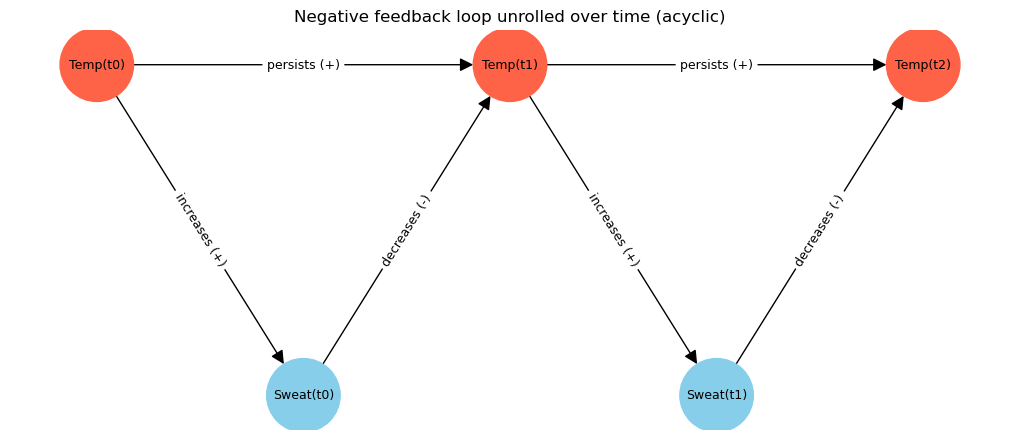

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
edges = [
    ('Temp(t0)',  'Sweat(t0)', 'increases (+)'),   # high temperature causes sweating
    ('Sweat(t0)', 'Temp(t1)',  'decreases (-)'),   # sweating lowers the NEXT temperature
    ('Temp(t0)',  'Temp(t1)',  'persists (+)'),    # temperature carries over in time
    ('Temp(t1)',  'Sweat(t1)', 'increases (+)'),
    ('Sweat(t1)', 'Temp(t2)',  'decreases (-)'),
    ('Temp(t1)',  'Temp(t2)',  'persists (+)'),
]
for u, v, label in edges:
    G.add_edge(u, v, label=label)

print("Is DAG:", nx.is_directed_acyclic_graph(G))   # True -> no cycles

pos = {'Temp(t0)': (0, 1), 'Sweat(t0)': (1, 0), 'Temp(t1)': (2, 1),
       'Sweat(t1)': (3, 0), 'Temp(t2)': (4, 1)}
colors = ['tomato' if n.startswith('Temp') else 'skyblue' for n in G]

plt.figure(figsize=(10, 4))
nx.draw(G, pos, with_labels=True, node_color=colors, node_size=2800,
        font_size=9, arrowsize=20)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'label'),
                             font_size=9)
plt.title('Negative feedback loop unrolled over time (acyclic)')
plt.show()

A direct drawing of this loop would be Temperature → Sweating → Temperature, which is a cycle, and a DAG cannot have two variables cause each other. I removed the cycle by indexing each variable by time. High body temperature at time t increases sweating at time t (a positive edge). Sweating at time t then decreases body temperature at the next time step, t+1 (a negative edge). I also added an edge Temp(t) → Temp(t+1), because body temperature carries over from one moment to the next.

The feedback is negative because the two edges in each round have opposite signs: (+) × (−) = (−). If temperature rises, sweating rises, which pushes the next temperature back down. This stabilizes the system around a set point, which is how the body maintains homeostasis. Every arrow points forward in time, so the graph is acyclic; I confirmed this with networkx.is_directed_acyclic_graph

---
2. Describe an example of a positive feedback loop.  This means that one things increases another while the second things also increases the first.

Is DAG: True


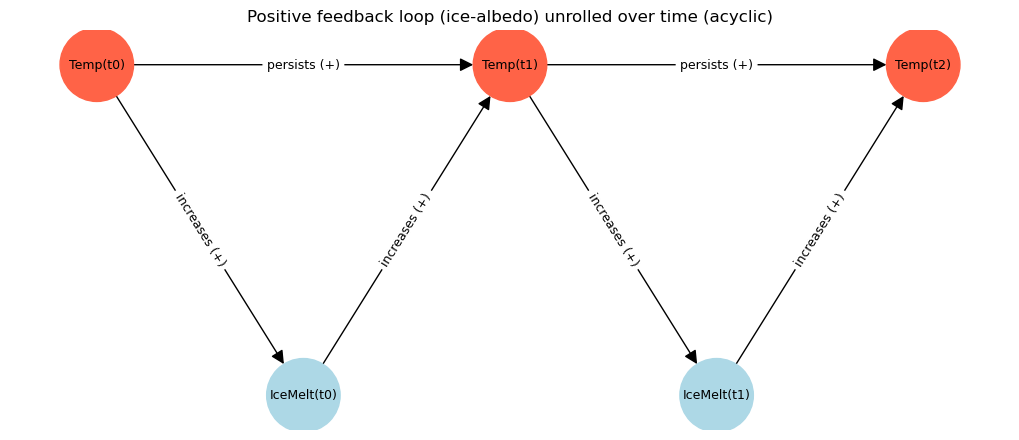

In [2]:
G2 = nx.DiGraph()
edges2 = [
    ('Temp(t0)',    'IceMelt(t0)', 'increases (+)'),   # warmer -> more ice melts
    ('IceMelt(t0)', 'Temp(t1)',    'increases (+)'),   # less ice -> less reflection -> warmer
    ('Temp(t0)',    'Temp(t1)',    'persists (+)'),
    ('Temp(t1)',    'IceMelt(t1)', 'increases (+)'),
    ('IceMelt(t1)', 'Temp(t2)',    'increases (+)'),
    ('Temp(t1)',    'Temp(t2)',    'persists (+)'),
]
for u, v, label in edges2:
    G2.add_edge(u, v, label=label)

print("Is DAG:", nx.is_directed_acyclic_graph(G2))

pos2 = {'Temp(t0)': (0, 1), 'IceMelt(t0)': (1, 0), 'Temp(t1)': (2, 1),
        'IceMelt(t1)': (3, 0), 'Temp(t2)': (4, 1)}
colors2 = ['tomato' if n.startswith('Temp') else 'lightblue' for n in G2]

plt.figure(figsize=(10, 4))
nx.draw(G2, pos2, with_labels=True, node_color=colors2, node_size=2800,
        font_size=9, arrowsize=20)
nx.draw_networkx_edge_labels(G2, pos2, edge_labels=nx.get_edge_attributes(G2, 'label'),
                             font_size=9)
plt.title('Positive feedback loop (ice-albedo) unrolled over time (acyclic)')
plt.show()

A classic positive feedback loop is the ice–albedo effect in climate. Ice and snow are bright and reflect most incoming sunlight back to space. When global temperature rises, some ice melts and exposes darker ocean or land underneath. Darker surfaces absorb more sunlight, which raises temperature further, which melts more ice. Each variable increases the other: Temperature → (+) Ice melt, and Ice melt → (+) Temperature.

As with the sweating example, this can't be drawn as Temperature ⇄ Ice melt in a DAG, because two variables cannot directly cause each other. So I unrolled it over time: Temp(t) → IceMelt(t) → Temp(t+1). Both edges are positive, so the product of signs is (+) × (+) = (+), and a small push grows instead of fading. That is the key contrast with Question 1: negative feedback (sweating) pulls the system back to a set point, while positive feedback amplifies a change until something outside the loop stops it. Here, that limit is running out of ice.


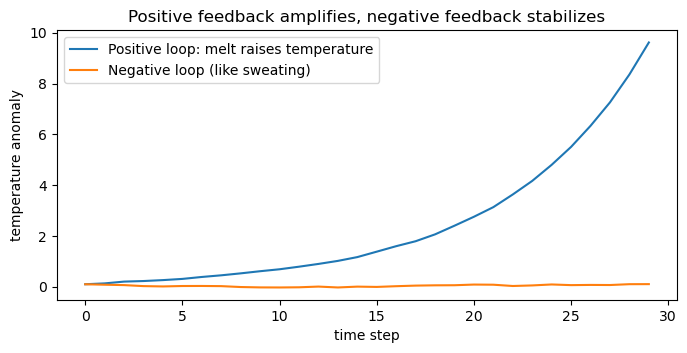

In [3]:
import numpy as np
np.random.seed(0)
steps = 30

def simulate(sign):
    temp = np.zeros(steps)
    temp[0] = 0.1                                            # small initial warming
    for t in range(1, steps):
        melt = 0.5 * temp[t-1] + np.random.normal(0, 0.02)  # warmer -> more melt
        temp[t] = temp[t-1] + sign * 0.3 * melt + np.random.normal(0, 0.02)
    return temp

plt.figure(figsize=(8, 3.5))
plt.plot(simulate(+1), label='Positive loop: melt raises temperature')
plt.plot(simulate(-1), label='Negative loop (like sweating)')
plt.xlabel('time step'); plt.ylabel('temperature anomaly'); plt.legend()
plt.title('Positive feedback amplifies, negative feedback stabilizes')
plt.show()

---
3. Draw a diagram for the following situation:

Lightning storms frighten away deer and bears, decreasing their population, and cause flowers to grow, increasing their population.
Bears eat deer, decreasing their population.
Deer eat flowers, decreasing their population.

Write a dataset that simulates this situation.  (Show the code.) Include noise / randomness in all cases.

Identify a backdoor path with one or more confounders for the relationship between deer and flowers.

Is DAG: True


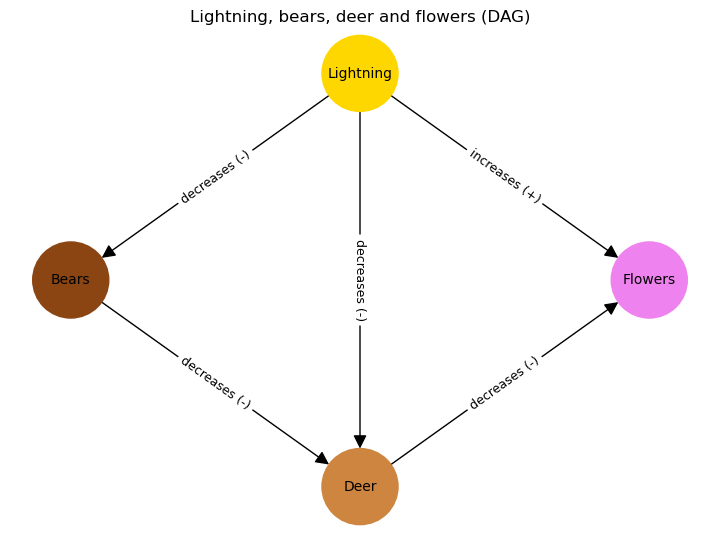

In [4]:
G3 = nx.DiGraph()
edges3 = [
    ('Lightning', 'Deer',    'decreases (-)'),   # storms frighten deer away
    ('Lightning', 'Bears',   'decreases (-)'),   # storms frighten bears away
    ('Lightning', 'Flowers', 'increases (+)'),   # storms help flowers grow
    ('Bears',     'Deer',    'decreases (-)'),   # bears eat deer
    ('Deer',      'Flowers', 'decreases (-)'),   # deer eat flowers
]
for u, v, label in edges3:
    G3.add_edge(u, v, label=label)

print("Is DAG:", nx.is_directed_acyclic_graph(G3))

pos3 = {'Lightning': (1, 2), 'Bears': (0, 1), 'Deer': (1, 0), 'Flowers': (2, 1)}
colors3 = {'Lightning': 'gold', 'Bears': 'saddlebrown', 'Deer': 'peru', 'Flowers': 'violet'}

plt.figure(figsize=(7, 5))
nx.draw(G3, pos3, with_labels=True, node_color=[colors3[n] for n in G3],
        node_size=3000, font_size=10, arrowsize=20)
nx.draw_networkx_edge_labels(G3, pos3, edge_labels=nx.get_edge_attributes(G3, 'label'),
                             font_size=9)
plt.title('Lightning, bears, deer and flowers (DAG)')
plt.show()

In [5]:
# Step 2 : Simulated dataset
import pandas as pd

np.random.seed(42)
n = 1000

lightning = np.random.poisson(3, n)                                      # storms per season (random)
bears     = 50  - 2 * lightning                + np.random.normal(0, 3, n)
deer      = 200 - 5 * lightning - 1.5 * bears  + np.random.normal(0, 10, n)
flowers   = 500 + 20 * lightning - 0.8 * deer  + np.random.normal(0, 25, n)

eco = pd.DataFrame({'lightning': lightning, 'bears': bears,
                    'deer': deer, 'flowers': flowers})
eco.head()

,lightning,bears,deer,flowers
0,4,42.250443,109.861923,460.202064
1,1,46.440075,114.396240,407.727590
2,3,42.923702,114.732903,476.041472
3,3,43.755432,133.549241,456.406405
4,2,45.452746,110.978781,471.376111


In [6]:
import statsmodels.formula.api as smf

# All paths between Deer and Flowers (ignoring arrow direction)
for path in nx.all_simple_paths(G3.to_undirected(), 'Deer', 'Flowers'):
    print(' - '.join(path))

naive    = smf.ols('flowers ~ deer', eco).fit().params['deer']
adjusted = smf.ols('flowers ~ deer + lightning', eco).fit().params['deer']
print(f"True effect of deer on flowers: -0.800")
print(f"Naive (no adjustment):          {naive:.3f}")
print(f"Adjusting for lightning:        {adjusted:.3f}")

Deer - Lightning - Flowers
Deer - Flowers
Deer - Bears - Lightning - Flowers
True effect of deer on flowers: -0.800
Naive (no adjustment):          -1.721
Adjusting for lightning:        -0.732


The diagram has three paths between Deer and Flowers. The direct causal path is Deer → Flowers (deer eat flowers). The main backdoor path is Deer ← Lightning → Flowers, where Lightning is a confounder: storms lower the deer population and also raise the flower population. A second backdoor path is Deer ← Bears ← Lightning → Flowers. Both backdoor paths run through Lightning.

In the simulation, the true effect of one more deer is −0.8 flowers. A naive regression of flowers on deer gives about −1.72, more than double the true effect. That's because in seasons with few deer there were usually many storms, and storms also raise flower counts, so deer look more harmful than they are. Adding lightning to the regression closes both backdoor paths and gives about −0.73, close to the true −0.8. Controlling for bears alone does not help (−1.80), because the path Deer ← Lightning → Flowers is still open.

---
4. Draw a diagram for a situation of your own invention.  The diagram should include at least four nodes, one confounder, and one collider.  Be sure that it is acyclic (no loops).  Which node would say is most like a treatment (X)?  Which is most like an outcome (Y)?

Is DAG: True
Confounder(s): ['Motivation']
Collider(s):   ['Honors']


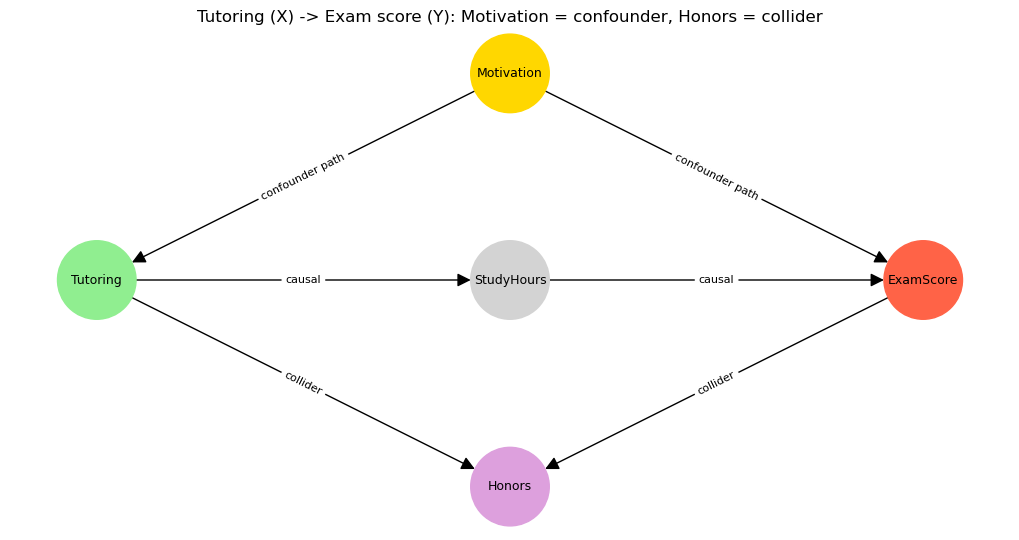

In [7]:
G4 = nx.DiGraph()
edges4 = [
    ('Motivation', 'Tutoring',   'confounder path'),  # motivated students sign up for tutoring
    ('Motivation', 'ExamScore',  'confounder path'),  # ...and also score higher on their own
    ('Tutoring',   'StudyHours', 'causal'),           # tutoring builds a study routine
    ('StudyHours', 'ExamScore',  'causal'),           # more study -> higher score
    ('Tutoring',   'Honors',     'collider'),         # tutor writes the honors recommendation
    ('ExamScore',  'Honors',     'collider'),         # high score also earns honors admission
]
for u, v, label in edges4:
    G4.add_edge(u, v, label=label)

print("Is DAG:", nx.is_directed_acyclic_graph(G4))   # True -> no loops

# A confounder has arrows INTO both X and Y; a collider has arrows coming in from both X and Y
X, Y = 'Tutoring', 'ExamScore'
confounders = [n for n in G4 if G4.has_edge(n, X) and G4.has_edge(n, Y)]
colliders   = [n for n in G4 if G4.has_edge(X, n) and G4.has_edge(Y, n)]
print("Confounder(s):", confounders)
print("Collider(s):  ", colliders)

pos4 = {'Motivation': (2, 2), 'Tutoring': (0, 1), 'StudyHours': (2, 1),
        'ExamScore': (4, 1), 'Honors': (2, 0)}
role = {'Motivation': 'gold', 'Tutoring': 'lightgreen', 'StudyHours': 'lightgray',
        'ExamScore': 'tomato', 'Honors': 'plum'}
colors4 = [role[n] for n in G4]

plt.figure(figsize=(10, 5))
nx.draw(G4, pos4, with_labels=True, node_color=colors4, node_size=3200,
        font_size=9, arrowsize=20)
nx.draw_networkx_edge_labels(G4, pos4, edge_labels=nx.get_edge_attributes(G4, 'label'),
                             font_size=8)
plt.title('Tutoring (X) -> Exam score (Y): Motivation = confounder, Honors = collider')
plt.show()

My example asks whether attending **tutoring** raises a student's **exam score**. The graph has five nodes. **Motivation** is the confounder: motivated students are more likely to sign up for tutoring (Motivation → Tutoring), and they also score higher on their own (Motivation → ExamScore). That makes a backdoor path, Tutoring ← Motivation → ExamScore. **StudyHours** is a mediator on the real causal path: Tutoring → StudyHours → ExamScore. **Honors** (admission to an honors program) is the collider: a student can get in through a tutor's recommendation or through a high exam score, so two arrows point into it (Tutoring → Honors ← ExamScore). Every arrow goes forward from cause to effect and none returns to an earlier node, so the graph is acyclic. `nx.is_directed_acyclic_graph` confirms this.

**Tutoring is the treatment (X)**, because it is the choice or intervention we would like to evaluate. **ExamScore is the outcome (Y)**, because it is the downstream result we care about. Motivation and Honors are neither. Motivation is a common *cause* of X and Y, and Honors is a common *effect* of X and Y.

The two special nodes need opposite handling. To remove confounding bias, we **should control for the confounder** (Motivation), which blocks the backdoor path. We **should not control for the collider** (Honors). A collider blocks its path on its own, but conditioning on it opens that path. For example, among honors students only, someone who got in without a high score most likely got in through tutoring. This creates a false negative link between tutoring and score. The simulation below shows both effects. The true effect is 6 points. The naive estimate is about 11 because motivation inflates it. Controlling for Motivation gives about 6. Adding Honors as a control, or keeping only honors students, pulls the estimate down to about 3.

In [8]:
rng = np.random.default_rng(4)
n = 10_000

motivation  = rng.normal(0, 1, n)
tutoring    = (motivation + rng.normal(0, 1, n) > 0).astype(float)    # 1 = attended tutoring
study_hours = 5 + 3 * tutoring + rng.normal(0, 1, n)                  # tutoring adds ~3 hrs/week
exam_score  = 60 + 2 * study_hours + 5 * motivation + rng.normal(0, 3, n)
honors      = (2 * tutoring + 0.2 * (exam_score - 70) + rng.normal(0, 1, n) > 2).astype(float)

def tutoring_coef(*controls, mask=None):
    """OLS coefficient on tutoring, optionally controlling for other variables / subsetting rows."""
    m = np.ones(n, bool) if mask is None else mask
    A = np.column_stack([np.ones(m.sum()), tutoring[m]] + [c[m] for c in controls])
    return np.linalg.lstsq(A, exam_score[m], rcond=None)[0][1]

print("True total effect of tutoring:                 6.00  (3 hrs x 2 pts/hr)")
print(f"Naive (no controls):                           {tutoring_coef():.2f}  <- confounded")
print(f"Control for Motivation (blocks backdoor):      {tutoring_coef(motivation):.2f}  <- correct")
print(f"Control for Motivation + Honors (collider):    {tutoring_coef(motivation, honors):.2f}  <- collider bias")
print(f"Only honors students, control for Motivation:  {tutoring_coef(motivation, mask=honors == 1):.2f}  <- collider bias")

True total effect of tutoring:                 6.00  (3 hrs x 2 pts/hr)
Naive (no controls):                           11.42  <- confounded
Control for Motivation (blocks backdoor):      6.02  <- correct
Control for Motivation + Honors (collider):    3.20  <- collider bias
Only honors students, control for Motivation:  2.86  <- collider bias
